In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [9]:

df = pd.read_csv("products.csv")

df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

pattern_counts = df_exploded['dark_pattern'].value_counts()

print(pattern_counts)

dark_pattern
Inflated Reference Pricing / Deceptive Strikethrough    110
Manipulative Promotional Badge                           65
False Urgency / Artificial Scarcity                      28
Bundled Add-on / Deceptive Quantity Push                 19
Name: count, dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25852\2949496692.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=pattern_counts.index, x=pattern_counts.values, palette="Set2")


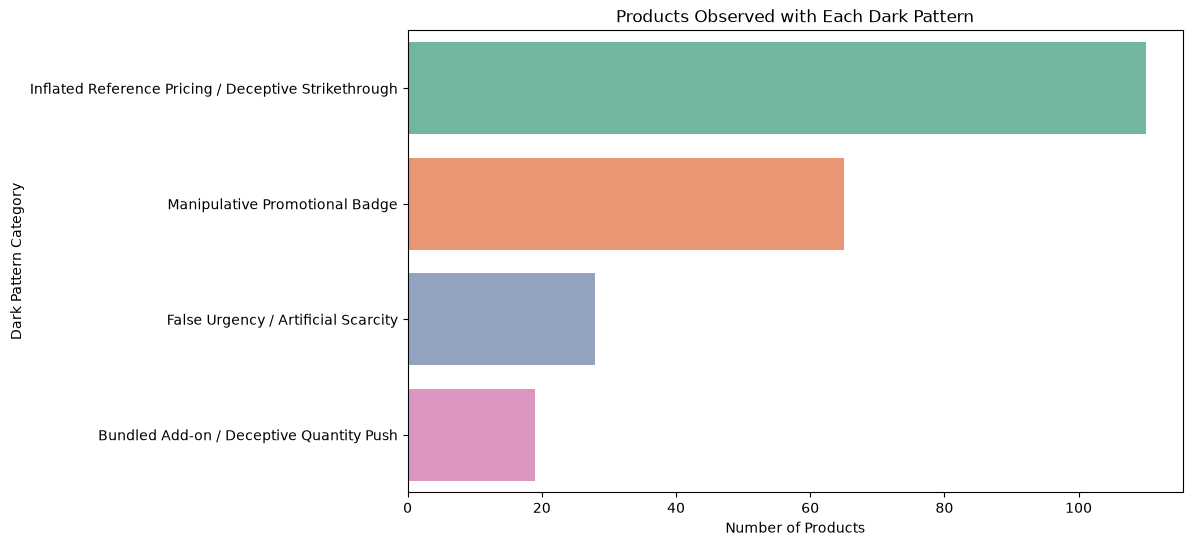

In [16]:
df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

# Count frequency of each dark pattern
pattern_counts = df_exploded['dark_pattern'].value_counts()

# Horizontal bar chart
plt.figure(figsize=(10,6))
sns.barplot(y=pattern_counts.index, x=pattern_counts.values, palette="Set2")
plt.xlabel("Number of Products")
plt.ylabel("Dark Pattern Category")
plt.title("Products Observed with Each Dark Pattern")
plt.show()


dark_pattern
Inflated Reference Pricing / Deceptive Strikethrough    68.750
Manipulative Promotional Badge                          40.625
False Urgency / Artificial Scarcity                     17.500
Bundled Add-on / Deceptive Quantity Push                11.875
Name: count, dtype: float64


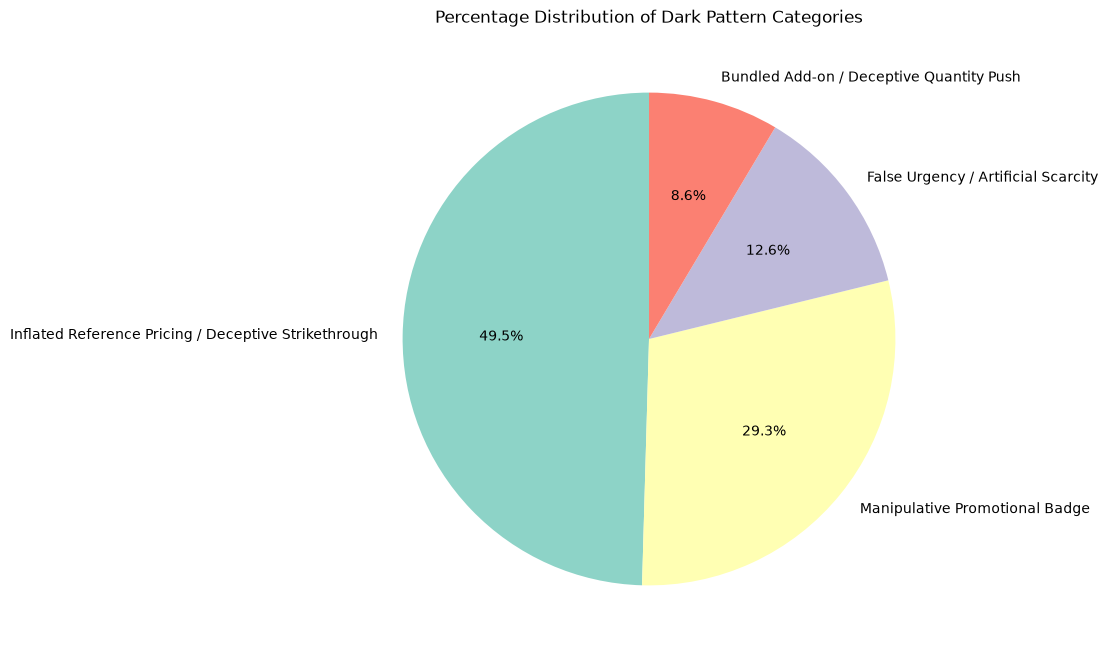

In [18]:
df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

# Count frequency of each dark pattern
pattern_counts = df_exploded['dark_pattern'].value_counts()

# Convert to percentage
pattern_percent = (pattern_counts / len(df)) * 100
print(pattern_percent)


plt.figure(figsize=(8,8))
plt.pie(pattern_percent, labels=pattern_percent.index,
        autopct='%1.1f%%', startangle=90, 
        colors=plt.cm.Set3.colors)
plt.title("Percentage Distribution of Dark Pattern Categories")
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25852\2800092800.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=avg_discount.index, x=avg_discount.values, palette="Set2")


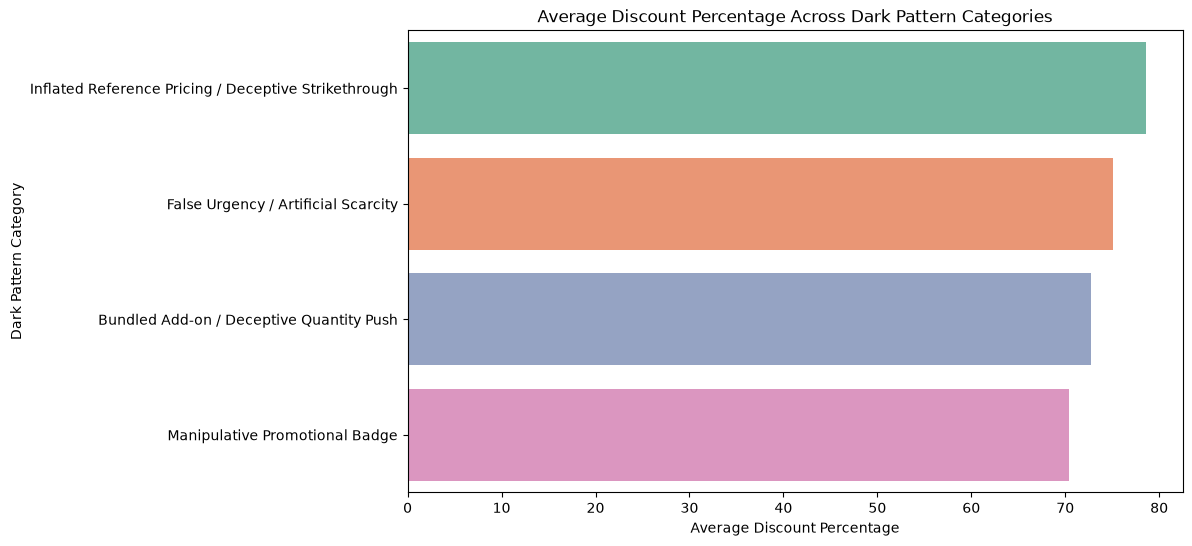

In [24]:
#How does the average discount percentage vary across dark-pattern categories?

# Split multiple dark patterns into separate rows
df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

# Convert discount_percentage to numeric (strip % if needed)
df_exploded['discount_percentage'] = df_exploded['discount_percentage'].str.replace('%','').astype(float)

# Calculate average discount percentage per dark pattern
avg_discount = df_exploded.groupby('dark_pattern')['discount_percentage'].mean().sort_values(ascending=False)

# Horizontal bar chart
plt.figure(figsize=(10,6))
sns.barplot(y=avg_discount.index, x=avg_discount.values, palette="Set2")
plt.xlabel("Average Discount Percentage")
plt.ylabel("Dark Pattern Category")
plt.title("Average Discount Percentage Across Dark Pattern Categories")
plt.show()


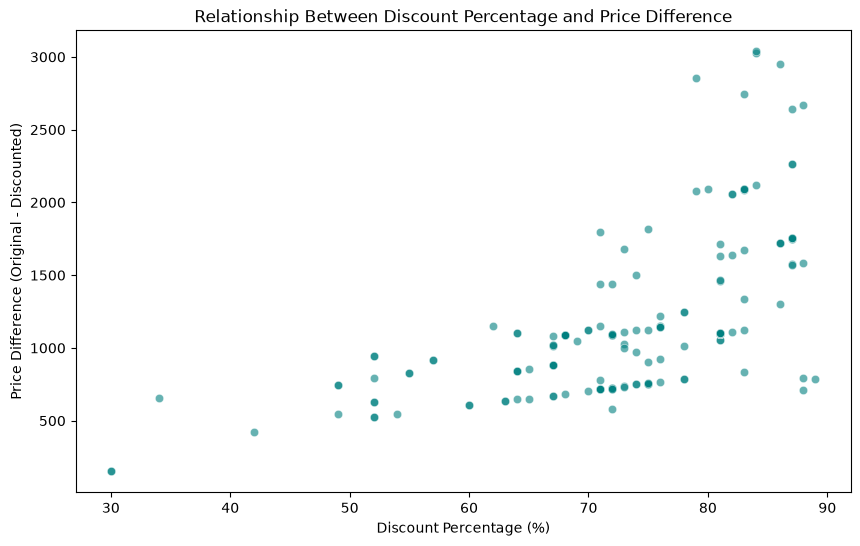

In [25]:
#Is there a relationship between discount percentage and the difference between original and discounted price?

# Clean discount percentage (remove % and convert to float if needed)
df['discount_percentage'] = df['discount_percentage'].str.replace('%','').astype(float)

# Compute price difference
df['price_diff'] = df['original_price'] - df['discounted_price']

# Scatter plot
plt.figure(figsize=(10,6))
sns.scatterplot(x='discount_percentage', y='price_diff', data=df, alpha=0.6, color="teal")

plt.xlabel("Discount Percentage (%)")
plt.ylabel("Price Difference (Original - Discounted)")
plt.title("Relationship Between Discount Percentage and Price Difference")
plt.show()


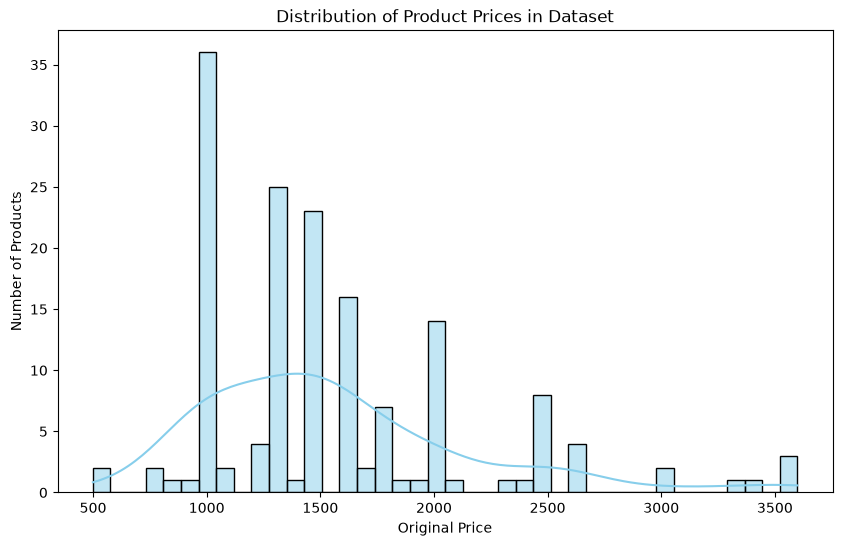

In [26]:
# What is the distribution of product prices in the dataset?

plt.figure(figsize=(10,6))
sns.histplot(df['original_price'], bins=40, kde=True, color="skyblue")

plt.xlabel("Original Price")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Prices in Dataset")
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25852\4092250779.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='dark_pattern', y='discounted_price', data=df_exploded, palette="Set2")


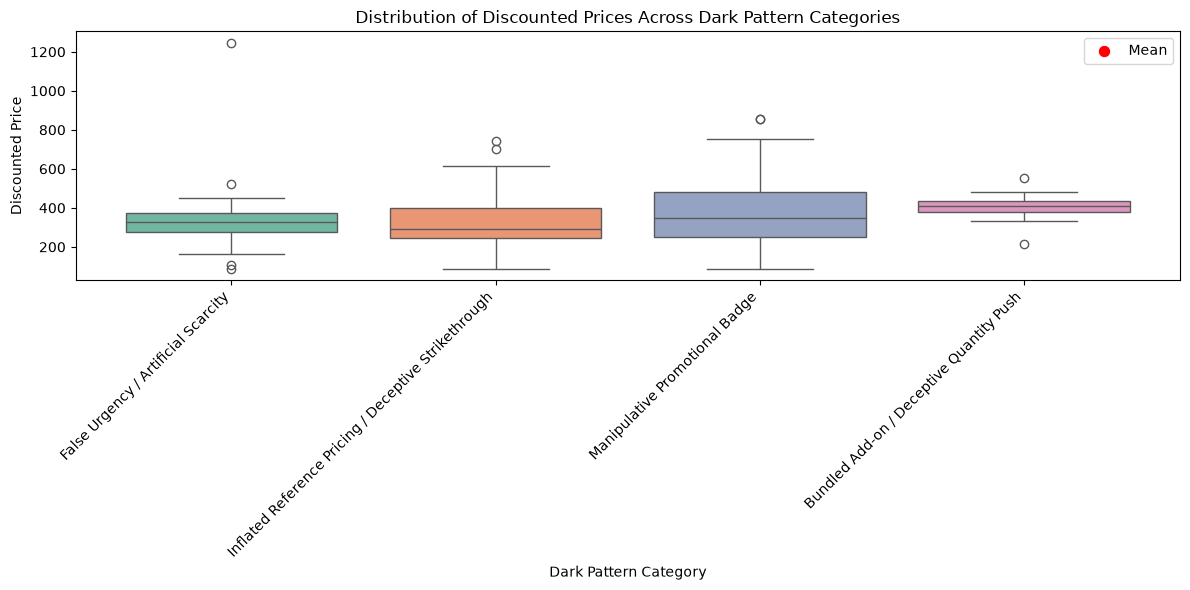

In [33]:
#How does the average discounted price differ across dark-pattern categories?

# Ensure discounted_price is numeric
df['discounted_price'] = pd.to_numeric(df['discounted_price'], errors='coerce')

# Ensure discounted_price is numeric
df['discounted_price'] = pd.to_numeric(df['discounted_price'], errors='coerce')

# Split multiple dark patterns into separate rows
df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

# Drop rows with missing values
df_exploded = df_exploded.dropna(subset=['discounted_price', 'dark_pattern'])

# Boxplot of discounted prices by dark pattern category
plt.figure(figsize=(12,6))
sns.boxplot(x='dark_pattern', y='discounted_price', data=df_exploded, palette="Set2")

# Overlay mean as a point for clarity
mean_values = df_exploded.groupby('dark_pattern')['discounted_price'].mean()
sns.scatterplot(x=mean_values.index, y=mean_values.values, 
                color='red', marker='o', s=80, label='Mean')

plt.xticks(rotation=45, ha='right')
plt.xlabel("Dark Pattern Category")
plt.ylabel("Discounted Price")
plt.title("Distribution of Discounted Prices Across Dark Pattern Categories")
plt.legend()
plt.tight_layout()
plt.show()



C:\Users\ASUS\AppData\Local\Temp\ipykernel_25852\3983322973.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=manip_counts.index.map({True:'Contains Manipulation', False:'No Manipulation'}),


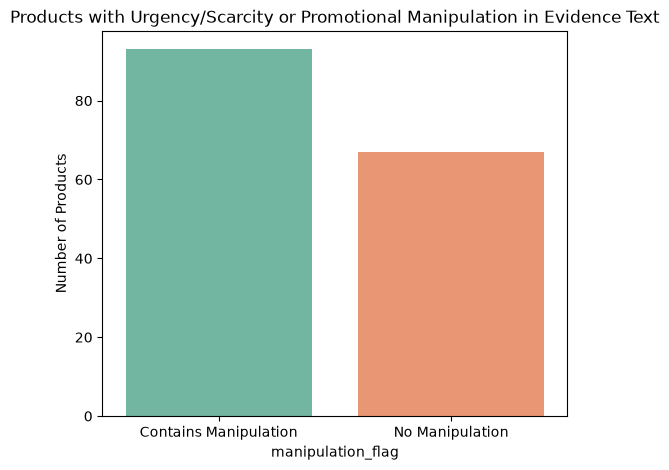

In [34]:
#How many products contain evidence of urgency/scarcity or other promotional manipulation in their evidence text?

# Define keywords for urgency/scarcity and promotional manipulation
keywords = ['Only few left', 'Hot Deal', 'Big Billion Days Price', 'Lowest price since launch', 'Value 365']

# Create a new column flagging presence of manipulation
df['manipulation_flag'] = df['evidence_text'].apply(
    lambda x: any(keyword in str(x) for keyword in keywords)
)

# Count products with vs. without manipulation
manip_counts = df['manipulation_flag'].value_counts()

# Bar chart
plt.figure(figsize=(6,5))
sns.barplot(x=manip_counts.index.map({True:'Contains Manipulation', False:'No Manipulation'}),
            y=manip_counts.values, palette="Set2")

plt.ylabel("Number of Products")
plt.title("Products with Urgency/Scarcity or Promotional Manipulation in Evidence Text")
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25852\1950213662.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


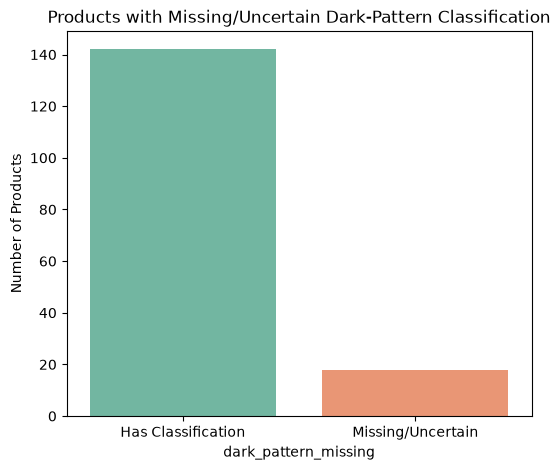

In [35]:
#How many products have a missing/uncertain dark-pattern classification?

# Flag products with missing/uncertain dark-pattern classification
df['dark_pattern_missing'] = df['detected_dark_patterns'].isna() | (df['detected_dark_patterns'].str.strip() == 'None')

# Count products with vs. without missing classification
missing_counts = df['dark_pattern_missing'].value_counts()

# Bar chart
plt.figure(figsize=(6,5))
sns.barplot(
    x=missing_counts.index.map({True:'Missing/Uncertain', False:'Has Classification'}),
    y=missing_counts.values,
    palette="Set2"
)

plt.ylabel("Number of Products")
plt.title("Products with Missing/Uncertain Dark-Pattern Classification")
plt.show()


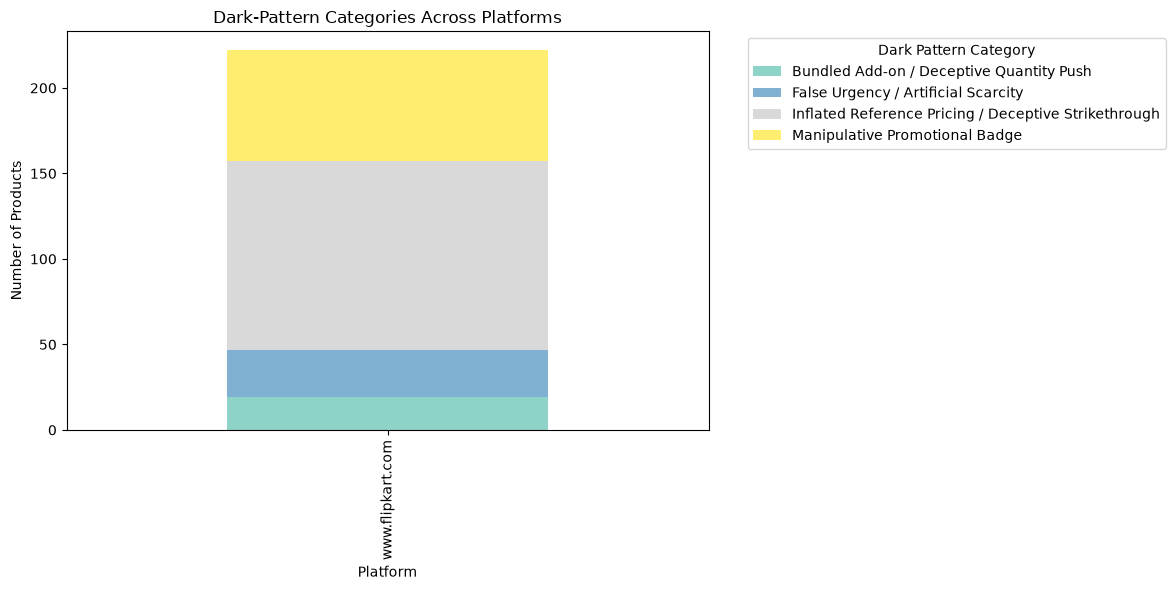

In [41]:
#Which dark-pattern categories are most common within each platform?

# Extract platform name from source_url (e.g., "flipkart.com")
df['platform'] = df['source_url'].str.extract(r'//([^/]+)/')[0]

# Split multiple dark patterns into separate rows
df_exploded = df.assign(
    dark_pattern=df['detected_dark_patterns'].str.split('; ')
).explode('dark_pattern')

# Count products per platform and dark pattern
pattern_platform_counts = df_exploded.groupby(['platform','dark_pattern']).size().unstack(fill_value=0)

# Stacked bar chart
pattern_platform_counts.plot(kind='bar', stacked=True, figsize=(12,6), colormap="Set3")

plt.xlabel("Platform")
plt.ylabel("Number of Products")
plt.title("Dark-Pattern Categories Across Platforms")
plt.legend(title="Dark Pattern Category", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
